# Day 97 — What is a Perceptron? Perceptron vs Neuron | Geometric Intuition

In this notebook we will:
1. Build a **Perceptron from scratch** (NumPy)
2. Implement **AND, OR, NOT** gates
3. Watch the **learning rule** move the decision boundary
4. Understand the **geometry**: weight vector, bias, signed distance
5. Show why **XOR fails** and how two layers fix it
6. Compare **Perceptron vs sigmoid neuron**, and with scikit-learn

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.linear_model import Perceptron as SkPerceptron

np.random.seed(42)

## 1. Perceptron from scratch

`z = w·x + b`, then `ŷ = 1 if z >= 0 else 0`.

Learning rule on each sample: `w ← w + η(y − ŷ)x`, `b ← b + η(y − ŷ)`.

In [2]:
class Perceptron:
    def __init__(self, n_features, lr=0.1):
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.lr = lr
        self.history = []          # stores (w, b) after each epoch

    def net_input(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return (self.net_input(X) >= 0).astype(int)     # step function

    def fit(self, X, y, epochs=20, verbose=False):
        for epoch in range(epochs):
            errors = 0
            for xi, yi in zip(X, y):
                y_hat = self.predict(xi.reshape(1, -1))[0]
                update = self.lr * (yi - y_hat)
                self.w += update * xi
                self.b += update
                errors += int(update != 0)
            self.history.append((self.w.copy(), self.b))
            if verbose:
                print(f"Epoch {epoch+1:2d}: mistakes = {errors}, w = {self.w.round(3)}, b = {self.b:.3f}")
            if errors == 0:        # converged
                break
        return self

## 2. Logic gates with a perceptron

First with hand-chosen weights, then by learning them.

In [3]:
inputs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

def gate(w, b):
    p = Perceptron(2); p.w = np.array(w, dtype=float); p.b = b
    return p.predict(inputs)

print("x1 x2 | AND OR")
and_out = gate([1, 1], -1.5)
or_out  = gate([1, 1], -0.5)
for (x1, x2), a, o in zip(inputs, and_out, or_out):
    print(f" {x1}  {x2} |  {a}   {o}")

# NOT gate (1 input)
p_not = Perceptron(1); p_not.w = np.array([-1.0]); p_not.b = 0.5
print("\nNOT 0 ->", p_not.predict(np.array([[0]]))[0], "| NOT 1 ->", p_not.predict(np.array([[1]]))[0])

x1 x2 | AND OR
 0  0 |  0   0
 0  1 |  0   1
 1  0 |  0   1
 1  1 |  1   1

NOT 0 -> 1 | NOT 1 -> 0


In [4]:
# Learn the gates from data instead of choosing the weights by hand
y_and = np.array([0, 0, 0, 1])
y_or  = np.array([0, 1, 1, 1])

p_and = Perceptron(2, lr=0.1).fit(inputs, y_and, epochs=50)
p_or  = Perceptron(2, lr=0.1).fit(inputs, y_or,  epochs=50)

print("Learned AND -> w =", p_and.w.round(2), "b =", round(p_and.b, 2), "pred =", p_and.predict(inputs))
print("Learned OR  -> w =", p_or.w.round(2),  "b =", round(p_or.b, 2),  "pred =", p_or.predict(inputs))

Learned AND -> w = [0.2 0.1] b = -0.2 pred = [0 0 0 1]
Learned OR  -> w = [0.1 0.1] b = -0.1 pred = [0 1 1 1]


## 3. Train on 2D data and watch the boundary move

For two inputs the boundary `w1·x1 + w2·x2 + b = 0` is the line
`x2 = −(w1/w2)·x1 − b/w2`.

In [5]:
X, y = make_blobs(n_samples=100, centers=[[0, 0], [4, 4]], cluster_std=1.0, random_state=1)

model = Perceptron(2, lr=0.1).fit(X, y, epochs=30, verbose=True)
print("\nAccuracy:", (model.predict(X) == y).mean())

Epoch  1: mistakes = 10, w = [0.283 0.284], b = -0.600
Epoch  2: mistakes = 1, w = [0.117 0.21 ], b = -0.700
Epoch  3: mistakes = 0, w = [0.117 0.21 ], b = -0.700

Accuracy: 1.0


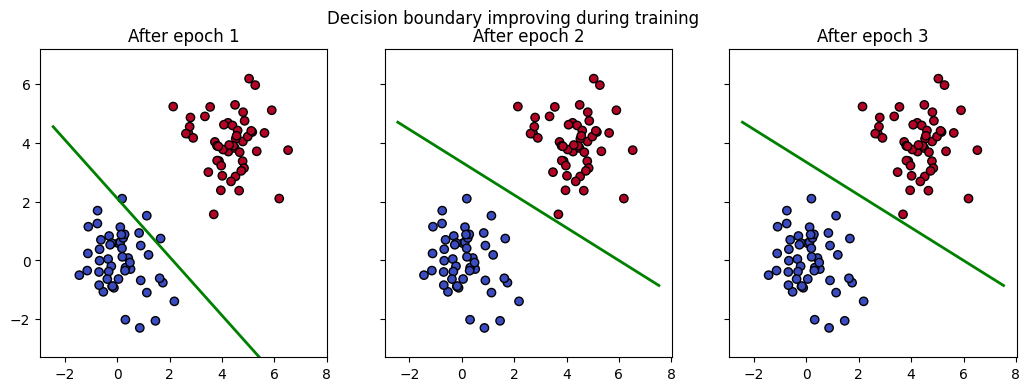

In [6]:
def boundary_line(w, b, x_vals):
    # solve w1*x1 + w2*x2 + b = 0 for x2
    if abs(w[1]) < 1e-9:
        return None
    return -(w[0] / w[1]) * x_vals - b / w[1]

x_vals = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 100)

epochs_to_show = list(range(min(len(model.history), 4)))
fig, axes = plt.subplots(1, len(epochs_to_show), figsize=(4.2 * len(epochs_to_show), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, e in zip(axes, epochs_to_show):
    w, b = model.history[e]
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k")
    line = boundary_line(w, b, x_vals)
    if line is not None:
        ax.plot(x_vals, line, "g-", lw=2)
    ax.set_ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)
    ax.set_title(f"After epoch {e+1}")
plt.suptitle("Decision boundary improving during training"); plt.show()

## 4. Geometric intuition

- **w** is the *normal vector* (perpendicular) to the boundary and points toward class 1.
- **b** shifts the boundary. Its distance from the origin is `|b| / ||w||`.
- The signed distance of a point is `(w·x + b) / ||w||`.

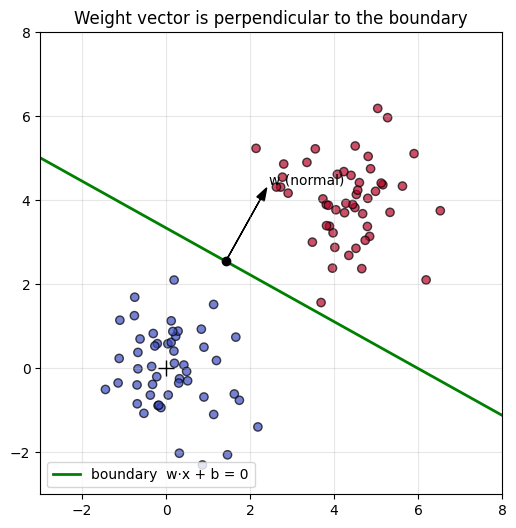

w = [0.117 0.21 ] | b = -0.7
Distance of boundary from origin = |b|/||w|| = 2.918


In [7]:
w, b = model.w, model.b
x_vals = np.linspace(-3, 8, 100)

plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", alpha=0.7)
plt.plot(x_vals, boundary_line(w, b, x_vals), "g-", lw=2, label="boundary  w·x + b = 0")

# closest point on the boundary to the origin
foot = -b * w / np.dot(w, w)
plt.arrow(foot[0], foot[1], w[0] / np.linalg.norm(w) * 2, w[1] / np.linalg.norm(w) * 2,
          head_width=0.2, color="black", length_includes_head=True)
plt.text(foot[0] + w[0] / np.linalg.norm(w) * 2.1, foot[1] + w[1] / np.linalg.norm(w) * 2.1, "w (normal)")
plt.plot(*foot, "ko"); plt.plot(0, 0, "k+", ms=12)
plt.xlim(-3, 8); plt.ylim(-3, 8); plt.gca().set_aspect("equal")
plt.legend(loc="lower left"); plt.title("Weight vector is perpendicular to the boundary"); plt.grid(alpha=0.3)
plt.show()

print("w =", w.round(3), "| b =", round(b, 3))
print("Distance of boundary from origin = |b|/||w|| =", round(abs(b) / np.linalg.norm(w), 3))

In [8]:
# Signed distance of a few points
test_points = np.array([[5.0, 5.0], [-1.0, -1.0], [2.0, 2.0], [4.0, 0.0]])
signed_dist = (test_points @ w + b) / np.linalg.norm(w)
for pt, d, pred in zip(test_points, signed_dist, model.predict(test_points)):
    side = "class 1 side" if d > 0 else "class 0 side"
    print(f"point {pt} -> signed distance = {d:6.2f} -> {side} (predicted {pred})")

# Check that w is perpendicular to the boundary direction
direction = np.array([w[1], -w[0]])           # a vector lying along the boundary
print("\nDot product of w and boundary direction:", round(float(np.dot(w, direction)), 10))

point [5. 5.] -> signed distance =   3.88 -> class 1 side (predicted 1)
point [-1. -1.] -> signed distance =  -4.28 -> class 0 side (predicted 0)
point [2. 2.] -> signed distance =  -0.20 -> class 0 side (predicted 0)
point [4. 0.] -> signed distance =  -0.97 -> class 0 side (predicted 0)

Dot product of w and boundary direction: 0.0


### Effect of the bias

Same weights, different biases: the line shifts without rotating.

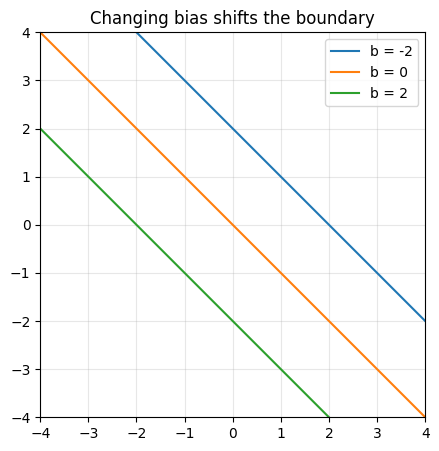

In [9]:
w_fixed = np.array([1.0, 1.0])
x_vals = np.linspace(-4, 4, 100)
plt.figure(figsize=(5, 5))
for b_val in [-2, 0, 2]:
    plt.plot(x_vals, boundary_line(w_fixed, b_val, x_vals), label=f"b = {b_val}")
plt.xlim(-4, 4); plt.ylim(-4, 4); plt.gca().set_aspect("equal"); plt.grid(alpha=0.3)
plt.title("Changing bias shifts the boundary"); plt.legend(); plt.show()

## 5. The XOR problem

No single line separates XOR, so the perceptron never reaches 100% accuracy.

Predictions: [1 1 0 0] | True: [0 1 1 0]
Accuracy   : 0.5


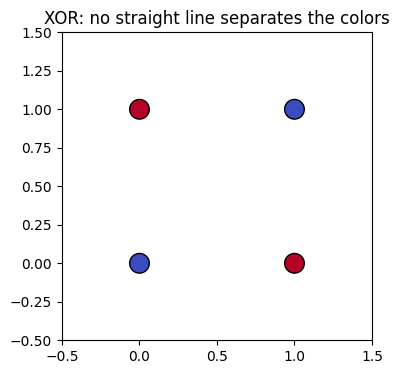

In [10]:
y_xor = np.array([0, 1, 1, 0])
p_xor = Perceptron(2, lr=0.1).fit(inputs, y_xor, epochs=100)
print("Predictions:", p_xor.predict(inputs), "| True:", y_xor)
print("Accuracy   :", (p_xor.predict(inputs) == y_xor).mean())

plt.figure(figsize=(4, 4))
plt.scatter(inputs[:, 0], inputs[:, 1], c=y_xor, cmap="coolwarm", s=200, edgecolor="k")
plt.title("XOR: no straight line separates the colors"); plt.xlim(-0.5, 1.5); plt.ylim(-0.5, 1.5)
plt.show()

### Fixing XOR with two layers

`XOR(x1, x2) = (x1 OR x2) AND NOT (x1 AND x2)`

Hidden layer: one perceptron computes OR, another computes NAND. Output perceptron: AND of the two.
Weights below are set by hand to show that a **2-layer network** solves XOR.

In [11]:
def step(z): return (z >= 0).astype(int)

W_hidden = np.array([[ 1.0,  1.0],      # OR
                     [-1.0, -1.0]])     # NAND
b_hidden = np.array([-0.5, 1.5])

W_out = np.array([1.0, 1.0])            # AND of the two hidden units
b_out = -1.5

hidden = step(inputs @ W_hidden.T + b_hidden)
output = step(hidden @ W_out + b_out)

print("x1 x2 | OR NAND | XOR")
for (x1, x2), h, o in zip(inputs, hidden, output):
    print(f" {x1}  {x2} |  {h[0]}   {h[1]}   |  {o}")
print("\nMatches XOR:", np.array_equal(output, y_xor))

x1 x2 | OR NAND | XOR
 0  0 |  0   1   |  0
 0  1 |  1   1   |  1
 1  0 |  1   1   |  1
 1  1 |  1   0   |  0

Matches XOR: True


## 6. Perceptron vs a sigmoid neuron

Same `z = w·x + b`, different activation: the step gives a hard 0/1, the sigmoid gives a smooth value.

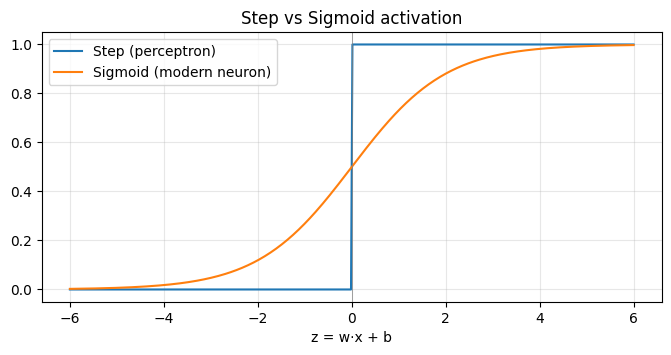

Step gradient (almost everywhere): 0   -> gradient descent cannot learn from it
Sigmoid gradient at z=0 : 0.25 -> smooth, trainable by gradient descent


In [12]:
z = np.linspace(-6, 6, 400)
step_out = (z >= 0).astype(float)
sigmoid_out = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 3.5))
plt.plot(z, step_out, label="Step (perceptron)")
plt.plot(z, sigmoid_out, label="Sigmoid (modern neuron)")
plt.axvline(0, color="gray", lw=0.5); plt.grid(alpha=0.3); plt.legend()
plt.title("Step vs Sigmoid activation"); plt.xlabel("z = w·x + b"); plt.show()

# Gradients: step has zero gradient almost everywhere, sigmoid does not
sig_grad = sigmoid_out * (1 - sigmoid_out)
print("Step gradient (almost everywhere): 0   -> gradient descent cannot learn from it")
print("Sigmoid gradient at z=0 :", sig_grad[len(z)//2].round(3), "-> smooth, trainable by gradient descent")

## 7. Compare with scikit-learn's Perceptron

In [13]:
sk = SkPerceptron(max_iter=1000, eta0=0.1, random_state=42).fit(X, y)
print("Scratch accuracy     :", (model.predict(X) == y).mean())
print("scikit-learn accuracy:", sk.score(X, y))
print("scikit-learn w =", sk.coef_[0].round(3), "b =", sk.intercept_.round(3))
print("Scratch w          =", model.w.round(3), "b =", round(model.b, 3))

Scratch accuracy     : 1.0
scikit-learn accuracy: 1.0
scikit-learn w = [0.135 0.088] b = [-0.4]
Scratch w          = [0.117 0.21 ] b = -0.7


## Summary

- Perceptron: `ŷ = step(w·x + b)`, a binary linear classifier
- Geometry: boundary `w·x + b = 0`, **w ⟂ boundary**, **b shifts** it
- Learning rule converges only for **linearly separable** data
- XOR is not linearly separable, so we need **multiple layers**
- Modern neurons use **smooth activations** so they can be trained with gradient descent

## Practice exercises

1. Train the perceptron on `make_blobs` with `cluster_std=3` (overlapping classes). Does it converge? What happens to the mistakes per epoch?
2. Implement a **NAND** gate and a **NOR** gate with hand-chosen weights.
3. Set `b = 0` in the 2D example. Why can't the boundary fit data that is far from the origin?
4. Add a `predict_proba`-style output using the sigmoid on `z`. How is it different from the step output?
5. Try the learning rate `lr = 1.0` and `lr = 0.001`. Does the boundary change at convergence?